# This is a sample Jupyter Notebook

Below is an example of a code cell. 
Put your cursor into the cell and press Shift+Enter to execute it and select the next one, or click 'Run Cell' button.

Press Double Shift to search everywhere for classes, files, tool windows, actions, and settings.

To learn more about Jupyter Notebooks in PyCharm, see [help](https://www.jetbrains.com/help/pycharm/ipython-notebook-support.html).
For an overview of PyCharm, go to Help → Learn IDE features or refer to [our documentation](https://www.jetbrains.com/help/pycharm/getting-started.html).

In [ ]:
%load_ext autoreload
%autoreload 2
# these make it so that if you change the files you import you won't need to restart the Jupyter Notebook kernel

from analytic_formulation import OlengEquations, Q_

# --- Params ---
params = {
    'rd':      Q_(0.316, 'm'),
    'nP':      Q_(4000, 'rpm'),
    'a':       1.2,
    'b':       1.0,
    'c':       0.5,
    'PP':      Q_(100.0, 'kW'),
    'mv':      Q_(1500.0, 'kg'),
    'g':       Q_(9.81, 'm/s**2'),
    'fr':      0.015,                    # plain float, avoids pint friction
    'rho_a':   Q_(1.225, 'kg/m**3'),
    'CD':      0.30,                     # plain float
    'Af':      Q_(2.2, 'm**2'),
    'gamma_m': 1.05,                     # plain float
    'eta_T':   0.92,                     # plain float
    'eta_o':   0.38,
    'HL':      Q_(44e6, 'J/kg'),
}



model = OlengEquations(params, initial_velocity=Q_(0.0, 'km/h').to('m/s'))




# Calculations
There is a problem in the formulation (formula 12 in the study):

$$ P_i = \frac{1}{\eta_T} \left( m_v \cdot g \cdot f_r \cdot \frac{v(t)}{3.6} + 0.5 \cdot \rho_a \cdot C_D \cdot A_f \cdot \left\{ \frac{v(t)}{3.6} \right\}^3 + m_v \cdot \gamma_m \cdot a(t) \right) $$
Where, in the final element for inertia, there is a unit problem and the correct formula should be:
$$ P_i = \frac{1}{\eta_T} \left( m_v g f_r + 0.5 \rho_a C_D A_f v^2 + m_v \gamma_m a \right) \cdot v $$
In the previous equations we did not sum power but force for the inertia.
$$ \text{Units} = [Mass] \cdot [Acceleration] = \textcolor{red}{\text{Newtons}} \text{ (Force)}$$



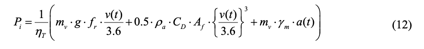

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from analytic_formulation import OlengEquations, Q_

delta_s    = Q_(500.0, 'm')
total_dist = Q_(5_000.0, 'm')
n_steps    = int(total_dist / delta_s)
v_cruise   = Q_(90.0, 'km/h').to('m/s')

# Use a dedicated model starting at cruise speed so the optimizer has a meaningful baseline
model_opt = OlengEquations(params, initial_velocity=v_cruise)

initial_guess = [0.0 for _ in range(n_steps)]


def fuel_objective(acceleration_profile):
    results = model_opt.run(acceleration_profile, delta_s, xi_ax=3.9, xi_n=1.0)

    total_fuel = results['fuel_cumulative_kg'].iloc[-1]

    # Penalise trajectories that deviate far from the target cruise speed
    v_final = results['velocity_ms'].iloc[-1]
    v_target_ms = v_cruise.to('m/s').magnitude
    penalty = 1e3 * (v_final - v_target_ms) ** 2

    return total_fuel + penalty


minimization = minimize(fuel_objective, initial_guess, method='nelder-mead')

print(fuel_objective(minimization.x))
print(minimization)
